In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time
from annoy import AnnoyIndex

In [3]:
np.random.seed(42)
n_points = 10000
X = np.random.rand(n_points, 2) * 100
query = X[np.random.randint(0, n_points)]

In [4]:
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact*1000, 4), "ms")

Exact NN index: [ 257 3852 2646]
Exact NN jarak: [0.         0.61266463 0.73982948]
Waktu Exact: 98.8469 ms


In [5]:
f = 2  
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann*1000, 4), "ms")


Annoy NN index: [257, 3852, 5250]
Annoy NN jarak: [np.float64(0.0), np.float64(0.612664626053517), np.float64(0.796481371231288)]
Waktu Annoy: 0.2215 ms


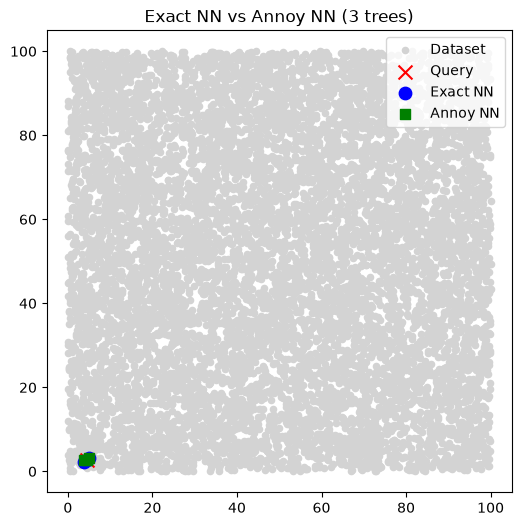

In [6]:
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN ditandai biru
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")

# Annoy NN ditandai hijau
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()